
# Crime and Public Safety Data Analysis

## Project Overview

This notebook presents an analysis of crime and public safety data using Python.

The analysis includes:
1. Dataset overview and exploration.
2. Data preprocessing and cleaning.
3. Descriptive statistical analysis.
4. Crime category frequency analysis.
5. Data visualization.
6. Interpretation of findings.

**Tools Used:** Python, Pandas, NumPy and Matplotlib.

**Dataset:** Simulated crime and public safety dataset containing 248 original records and 7 attributes.

**Purpose:** Academic analysis and demonstration of data analysis techniques.

**Data Disclaimer:** The dataset is simulated and does not represent actual crime statistics.


In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Display all columns in the notebook
pd.set_option("display.max_columns", None)

# Display charts directly inside the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

# Locate the dataset

possible_paths = [
    Path("data/crime_data.csv"),
    Path("../data/crime_data.csv")
]

dataset_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "Crime dataset could not be found."
    )

# Load the dataset
crime_data = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", crime_data.shape)

# Display the first five records
crime_data.head()


Dataset loaded successfully!
Dataset shape: (248, 7)


,Date,State,Crime_Type,Area_Type,Victim_Age,Reported_Cases,Arrests
0,2025-02-02,Meghalaya,Robbery,Urban,26.0,27,21
1,2025-10-10,Tripura,Burglary,Rural,39.0,17,9
2,2025-08-27,Meghalaya,Robbery,Rural,62.0,30,28
3,2025-06-10,Manipur,Cybercrime,Urban,NaN,24,10
4,2025-06-08,Manipur,Assault,Rural,68.0,21,3


In [3]:

# Display dataset information

print("Dataset Information:")
crime_data.info()

print("\nDataset Dimensions:")
print("Rows:", crime_data.shape[0])
print("Columns:", crime_data.shape[1])

print("\nColumn Names:")
print(crime_data.columns.tolist())

print("\nStatistical Description:")
crime_data.describe()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 248 entries, 0 to 247
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            248 non-null    str    
 1   State           244 non-null    str    
 2   Crime_Type      248 non-null    str    
 3   Area_Type       248 non-null    str    
 4   Victim_Age      243 non-null    float64
 5   Reported_Cases  248 non-null    int64  
 6   Arrests         248 non-null    int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 13.7 KB

Dataset Dimensions:
Rows: 248
Columns: 7

Column Names:
['Date', 'State', 'Crime_Type', 'Area_Type', 'Victim_Age', 'Reported_Cases', 'Arrests']

Statistical Description:


,Victim_Age,Reported_Cases,Arrests
count,243.000000,248.000000,248.000000
mean,44.502058,18.245968,8.616935
std,14.663547,7.606197,7.203409
min,18.000000,5.000000,0.000000
25%,34.000000,12.000000,2.750000
50%,45.000000,18.000000,7.000000
75%,57.000000,25.000000,13.000000
max,70.000000,30.000000,28.000000


In [4]:
# Check missing values in each column
print("Missing Values in Each Column:")
print(crime_data.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:")
print(crime_data.isnull().sum().sum())

# Check duplicate records
print("\nNumber of Duplicate Records:")
print(crime_data.duplicated().sum())

Missing Values in Each Column:
Date              0
State             4
Crime_Type        0
Area_Type         0
Victim_Age        5
Reported_Cases    0
Arrests           0
dtype: int64

Total Missing Values:
9

Number of Duplicate Records:
8


In [5]:
# Create a copy of the original dataset
cleaned_data = crime_data.copy()

# Step 1: Remove duplicate records
cleaned_data = cleaned_data.drop_duplicates()

# Step 2: Convert numerical columns into numeric format
numeric_columns = ["Victim_Age", "Reported_Cases", "Arrests"]

for column in numeric_columns:
    cleaned_data[column] = pd.to_numeric(
        cleaned_data[column], errors="coerce"
    )

# Step 3: Convert Date column into datetime format
cleaned_data["Date"] = pd.to_datetime(
    cleaned_data["Date"], errors="coerce"
)

# Step 4: Fill missing numerical values using median
for column in numeric_columns:
    cleaned_data[column] = cleaned_data[column].fillna(
        cleaned_data[column].median()
    )

# Step 5: Fill missing categorical and date values using mode
for column in cleaned_data.columns:
    if column not in numeric_columns:
        cleaned_data[column] = cleaned_data[column].fillna(
            cleaned_data[column].mode()[0]
        )

# Display cleaning results
print("Data cleaning completed successfully!")

print("\nOriginal Dataset Shape:", crime_data.shape)
print("Cleaned Dataset Shape:", cleaned_data.shape)

print("\nMissing Values After Cleaning:")
print(cleaned_data.isnull().sum())

print("\nDuplicate Records After Cleaning:")
print(cleaned_data.duplicated().sum())

cleaned_data.head()

Data cleaning completed successfully!

Original Dataset Shape: (248, 7)
Cleaned Dataset Shape: (240, 7)

Missing Values After Cleaning:
Date              0
State             0
Crime_Type        0
Area_Type         0
Victim_Age        0
Reported_Cases    0
Arrests           0
dtype: int64

Duplicate Records After Cleaning:
0


,Date,State,Crime_Type,Area_Type,Victim_Age,Reported_Cases,Arrests
0,2025-02-02,Meghalaya,Robbery,Urban,26.0,27,21
1,2025-10-10,Tripura,Burglary,Rural,39.0,17,9
2,2025-08-27,Meghalaya,Robbery,Rural,62.0,30,28
3,2025-06-10,Manipur,Cybercrime,Urban,45.0,24,10
4,2025-06-08,Manipur,Assault,Rural,68.0,21,3


In [6]:
# Select numerical columns
numeric_data = cleaned_data[
    ["Victim_Age", "Reported_Cases", "Arrests"]
]

# Calculate statistical measures
statistics = pd.DataFrame({
    "Mean": numeric_data.mean(),
    "Median": numeric_data.median(),
    "Standard Deviation": numeric_data.std(),
    "Minimum": numeric_data.min(),
    "Maximum": numeric_data.max()
})

# Display statistical summary
print("STATISTICAL ANALYSIS OF CRIME DATA")
display(statistics.round(2))

STATISTICAL ANALYSIS OF CRIME DATA


,Mean,Median,Standard Deviation,Minimum,Maximum
Victim_Age,44.41,45.0,14.43,18.0,70.0
Reported_Cases,18.23,18.0,7.56,5.0,30.0
Arrests,8.42,7.0,6.96,0.0,28.0


In [7]:
# Select categorical columns
categorical_columns = ["State", "Crime_Type", "Area_Type"]

# Calculate frequency distribution
for column in categorical_columns:

    print("\nFrequency Distribution of", column)

    frequency = cleaned_data[column].value_counts()

    display(frequency.to_frame(name="Frequency"))


Frequency Distribution of State


,Frequency
State,
Meghalaya,64
Mizoram,49
Tripura,47
Assam,41
Manipur,39



Frequency Distribution of Crime_Type


,Frequency
Crime_Type,
Burglary,54
Assault,54
Cybercrime,46
Theft,45
Robbery,41



Frequency Distribution of Area_Type


,Frequency
Area_Type,
Rural,123
Urban,117


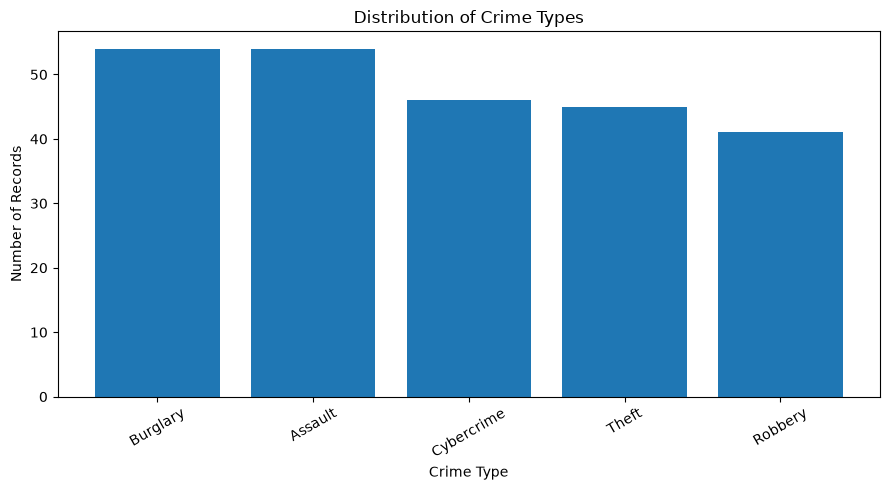

In [8]:
# Calculate frequency of each crime type
crime_frequency = cleaned_data["Crime_Type"].value_counts()

# Create the bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    crime_frequency.index,
    crime_frequency.values
)

# Add chart title and labels
plt.title("Distribution of Crime Types")
plt.xlabel("Crime Type")
plt.ylabel("Number of Records")

# Improve chart appearance
plt.xticks(rotation=30)
plt.tight_layout()

# Display the chart
plt.show()

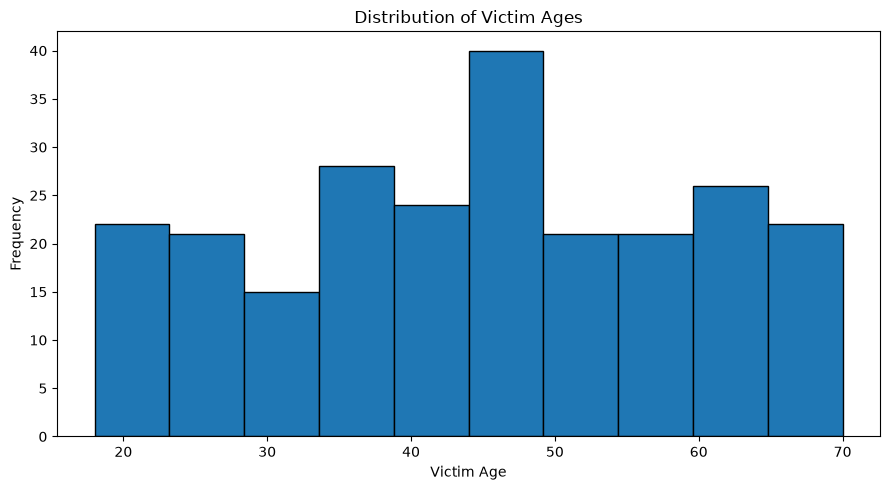

In [9]:
# Create a histogram for victim age
plt.figure(figsize=(9, 5))

plt.hist(
    cleaned_data["Victim_Age"],
    bins=10,
    edgecolor="black"
)

# Add chart title and labels
plt.title("Distribution of Victim Ages")
plt.xlabel("Victim Age")
plt.ylabel("Frequency")

# Improve chart appearance
plt.tight_layout()

# Display the histogram
plt.show()

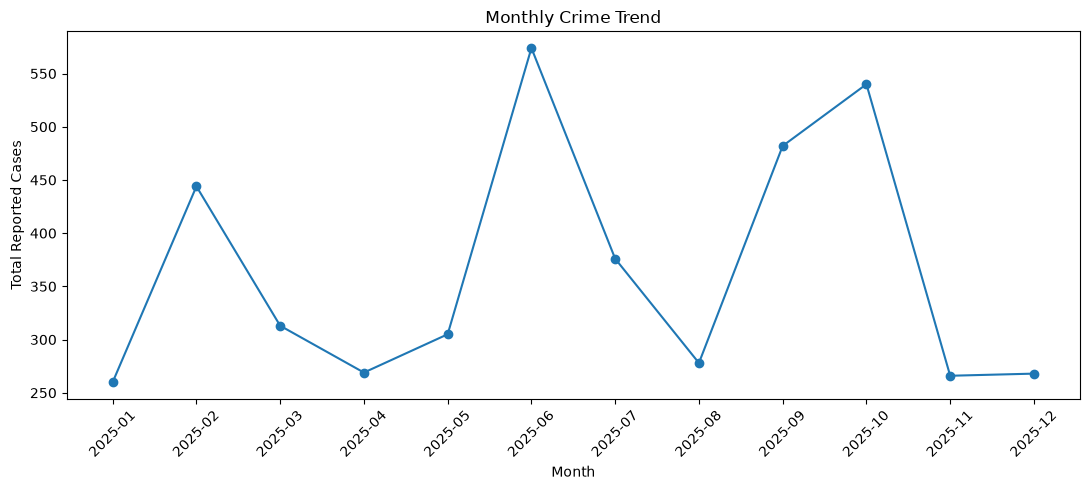

In [10]:
# Convert Date column into datetime format
cleaned_data["Date"] = pd.to_datetime(cleaned_data["Date"])

# Extract month and calculate total reported cases
monthly_crimes = (
    cleaned_data
    .groupby(cleaned_data["Date"].dt.to_period("M"))["Reported_Cases"]
    .sum()
)

# Create the line chart
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_crimes.index.astype(str),
    monthly_crimes.values,
    marker="o"
)

# Add chart title and labels
plt.title("Monthly Crime Trend")
plt.xlabel("Month")
plt.ylabel("Total Reported Cases")

# Rotate month labels
plt.xticks(rotation=45)

# Improve chart appearance
plt.tight_layout()

# Display the chart
plt.show()

In [11]:
# Identify the most frequent categories
most_common_crime = cleaned_data["Crime_Type"].value_counts().idxmax()
most_common_state = cleaned_data["State"].value_counts().idxmax()
most_common_area = cleaned_data["Area_Type"].value_counts().idxmax()

# Calculate average victim age
average_victim_age = cleaned_data["Victim_Age"].mean()

# Identify the month with the highest reported cases
peak_month = monthly_crimes.idxmax()
peak_cases = monthly_crimes.max()

# Display key observations
print("KEY OBSERVATIONS FROM CRIME DATA ANALYSIS")
print("------------------------------------------")

print("Most frequent crime type:", most_common_crime)
print("State with the most records:", most_common_state)
print("Most frequent area type:", most_common_area)
print("Average victim age:", round(average_victim_age, 2))
print("Month with highest reported cases:", peak_month)
print("Highest monthly reported cases:", peak_cases)

KEY OBSERVATIONS FROM CRIME DATA ANALYSIS
------------------------------------------
Most frequent crime type: Burglary
State with the most records: Meghalaya
Most frequent area type: Rural
Average victim age: 44.41
Month with highest reported cases: 2025-06
Highest monthly reported cases: 574


## 13. Data Ethics and Responsible Use

This project uses a simulated crime dataset created for educational and analytical purposes. It does not contain actual personal information or identifiable victim records.

The following ethical principles were considered:

1. **Privacy Protection:** No personally identifiable information is included.
2. **Responsible Interpretation:** The results must not be treated as actual crime statistics or used to make claims about real states or communities.
3. **Data Integrity:** Missing values and duplicate records were handled systematically.
4. **Transparency:** The dataset is identified as simulated, and the preprocessing and analytical methods are documented.
5. **Avoiding Bias:** Crime data can reflect reporting differences and institutional biases. Any future analysis using real-world data must consider these limitations.

## 14. Limitations of the Project

- The dataset is simulated and does not represent actual crime patterns.
- The analysis is primarily descriptive and does not predict future crime.
- The dataset covers a limited number of attributes.
- The project does not incorporate geographical mapping or external demographic information.

## 15. Future Scope

The system can be improved by:

- Integrating verified and legally accessible government crime datasets.
- Developing interactive dashboards.
- Adding geographical crime distribution maps.
- Applying machine learning techniques for carefully validated trend analysis.
- Introducing automated reports and advanced statistical analysis.

## 16. Conclusion

The project successfully demonstrates a modular Python-based Crime and Public Safety Data Analysis System. It performs data loading, preprocessing, statistical analysis, frequency distribution and visualization. The use of separate Python modules, unit testing and documented workflows makes the system easier to maintain, test and reproduce.